<a href="https://colab.research.google.com/github/stella-s-678/stella-s-678-DataScience-GenAI-Submissions/blob/main/Copy_of_7_01_Exploratory_Data_Analysis_Salary_Student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=1xqQczl0FG-qtNA2_WQYuWePW9oU8irqJ)

# 2.05 Exploratory Data Analysis (EDA)
In this exercise, you will explore a salary dataset (`EDA-DP.csv`) from the Week 7 Seminar Resources on myWBS. Work through the tasks in order. The setup cell below imports the libraries and allows you to upload the dataset.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from google.colab import files
upload = files.upload()

Saving EDA-DP.csv to EDA-DP.csv


**Task 1 — Load the data.** Read `EDA-DP.csv` into a pandas DataFrame and display the first few rows.

In [ ]:
df = pd.read_csv('EDA-DP.csv')
df.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2024,SE,FT,AI Engineer,202730,USD,202730,US,0,US,M
1,2024,SE,FT,AI Engineer,92118,USD,92118,US,0,US,M
2,2024,SE,FT,Data Engineer,130500,USD,130500,US,0,US,M
3,2024,SE,FT,Data Engineer,96000,USD,96000,US,0,US,M
4,2024,SE,FT,Machine Learning Engineer,190000,USD,190000,US,0,US,M


**Task 2 — Dataset size.** Find the number of rows and columns in the dataset.

In [ ]:
df.shape

(16534, 11)

**Task 3 — Dataset structure.** Inspect the column names, data types, and number of non-missing values.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16534 entries, 0 to 16533
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           16534 non-null  int64 
 1   experience_level    16534 non-null  object
 2   employment_type     16534 non-null  object
 3   job_title           16534 non-null  object
 4   salary              16534 non-null  int64 
 5   salary_currency     16534 non-null  object
 6   salary_in_usd       16534 non-null  int64 
 7   employee_residence  16534 non-null  object
 8   remote_ratio        16534 non-null  int64 
 9   company_location    16534 non-null  object
 10  company_size        16534 non-null  object
dtypes: int64(4), object(7)
memory usage: 1.4+ MB


**Task 4 — Missing data.** Check how many missing values there are in each column.

In [ ]:
df.isnull().sum()

,0
work_year,0
experience_level,0
employment_type,0
job_title,0
salary,0
salary_currency,0
salary_in_usd,0
employee_residence,0
remote_ratio,0
company_location,0


**Task 5 — Missing-data percentages.** Calculate the percentage of missing values for each column. Think about how you would handle missing data if you found any.

In [ ]:
df.isnull().mean() * 100

,0
work_year,0.0
experience_level,0.0
employment_type,0.0
job_title,0.0
salary,0.0
salary_currency,0.0
salary_in_usd,0.0
employee_residence,0.0
remote_ratio,0.0
company_location,0.0


**Task 6 — Duplicates.** Find how many rows are exact duplicates and how many are not. Would identical records necessarily be errors in this dataset?

In [ ]:
df.duplicated().value_counts()

,count
False,10113
True,6421


No, identical records are not necessarily errors. Different employees may have the same job title, experience level, salary and other characteristics. Therefore, duplicate records should be investigated before removal.

**Task 7 — Summary statistics.** Produce descriptive statistics for the numerical columns. What do the distributions tell you? Note that `salary` may use different currencies, whereas `salary_in_usd` is comparable across records.

In [ ]:
df.describe()

,work_year,salary,salary_in_usd,remote_ratio
count,16534.000000,1.653400e+04,16534.000000,16534.000000
mean,2023.226866,1.637270e+05,149686.777973,32.003750
std,0.713558,3.402057e+05,68505.293156,46.245158
min,2020.000000,1.400000e+04,15000.000000,0.000000
25%,2023.000000,1.017630e+05,101125.000000,0.000000
50%,2023.000000,1.422000e+05,141300.000000,0.000000
75%,2024.000000,1.872000e+05,185900.000000,100.000000
max,2024.000000,3.040000e+07,800000.000000,100.000000


The mean salary in USD ($149,687) is higher than the median ($141,300), suggesting a slightly right-skewed distribution. The relatively large standard deviation ($68,505) indicates considerable variation in salaries. The maximum salary ($800,000) also suggests the presence of potential outliers.

### Visualising the Data

**Task 8 — Bar chart.** Create a bar chart comparing the **average salary in USD** across experience levels (`EN`, `MI`, `SE`, `EX`). Add clear axis labels and a title. Which group has the highest average?

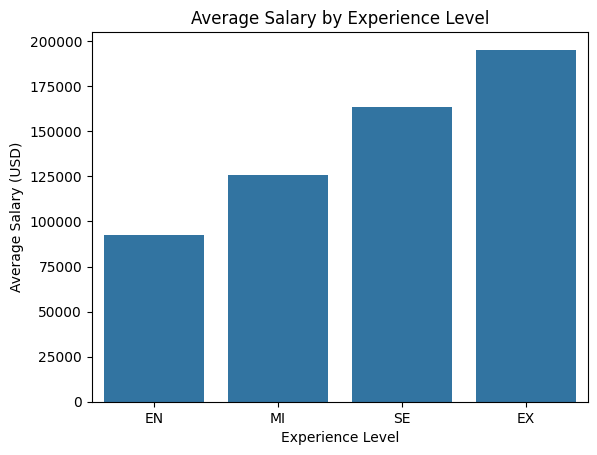

In [ ]:
sns.barplot(
    data=df,
    x='experience_level',
    y='salary_in_usd',
    order=['EN', 'MI', 'SE', 'EX'],
    errorbar=None
)

plt.xlabel('Experience Level')
plt.ylabel('Average Salary (USD)')
plt.title('Average Salary by Experience Level')
plt.show()

Executive-level employees have the highest average salary, followed by senior, mid-level and entry-level employees. This suggests a positive relationship between experience level and average salary.

**Task 9 — Scatter plot.** Make a scatter plot of `work_year` against `salary_in_usd`. Label the axes. What patterns do you notice? Are any points difficult to distinguish because they overlap?

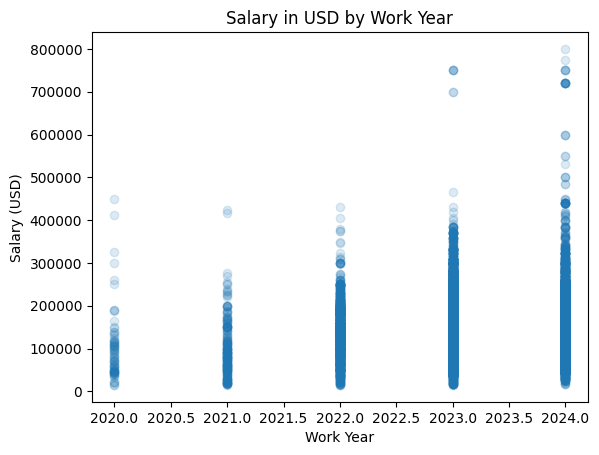

In [ ]:
plt.scatter(
    df['work_year'],
    df['salary_in_usd'],
    alpha=0.15
)

plt.xlabel('Work Year')
plt.ylabel('Salary (USD)')
plt.title('Salary in USD by Work Year')

plt.show()

The scatter plot shows a wider range of salaries in recent years, with several extremely high salaries in 2023 and 2024. Many points overlap because work_year is a discrete variable with only five values, making individual observations difficult to distinguish.

**Task 10 — Distribution.** Plot the distribution of `salary_in_usd`. Does it look approximately normal, skewed, or something else? Are there extreme values?

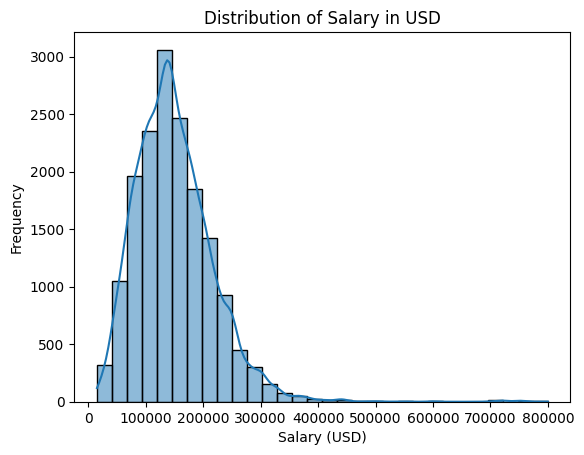

In [ ]:
sns.histplot(df['salary_in_usd'], bins=30, kde=True)

plt.xlabel('Salary (USD)')
plt.ylabel('Frequency')
plt.title('Distribution of Salary in USD')

plt.show()

The salary distribution is positively skewed, with most salaries concentrated between $50,000 and $250,000. A long right tail indicates the presence of a small number of extremely high salaries, reaching up to $800,000. The distribution is therefore not approximately normal.

**Task 11 — Pairwise relationships.** Visualize pairwise relationships among `salary_in_usd`, `work_year`, and `remote_ratio`, including distributions of the individual variables.

Try to compare the variables in one combined visualization. What relationships or patterns do you notice?

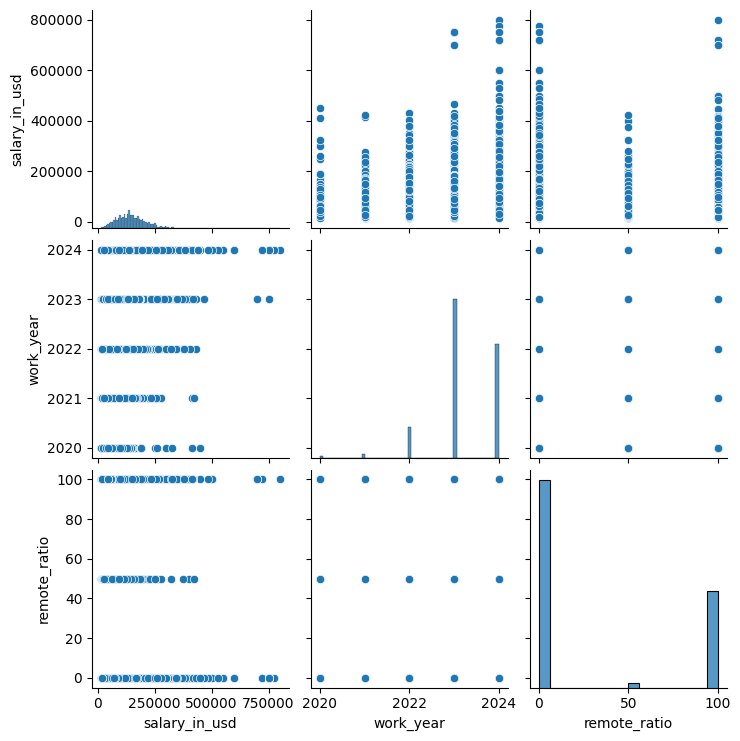

In [ ]:
sns.pairplot(
    df[['salary_in_usd', 'work_year', 'remote_ratio']],
    diag_kind='hist'
)

plt.show()

The pairplot shows that salary ranges vary across years, with more extreme high salaries appearing in recent years. Remote ratios are concentrated at 0, 50 and 100, with relatively few observations at 50. There is no clear linear relationship between salary and remote ratio. However, overlapping points make it difficult to identify detailed patterns.

**Task 12 — Remove a column.** Remove the original-currency `salary` column while retaining `salary_in_usd`, then inspect the updated DataFrame. Why might you choose to keep one salary column rather than both?

In [ ]:
df = df.drop(columns=['salary'])
df.head()

,work_year,experience_level,employment_type,job_title,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2024,SE,FT,AI Engineer,USD,202730,US,0,US,M
1,2024,SE,FT,AI Engineer,USD,92118,US,0,US,M
2,2024,SE,FT,Data Engineer,USD,130500,US,0,US,M
3,2024,SE,FT,Data Engineer,USD,96000,US,0,US,M
4,2024,SE,FT,Machine Learning Engineer,USD,190000,US,0,US,M


**Reflection.** What have you learned about the salary dataset? Which additional checks or visualizations would be useful before building a machine learning model?

Well done!